In [ ]:
import os
import sys
from IPython import get_ipython
import pandas as pd
import importlib

# Add parent directory to path to import from helpers
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))

# Only add if not already in path
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import helpers.process_data
from helpers.process_data import process_data, preprocess_data, in_fold_process_data

import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt


In [36]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')


In [32]:
# Data preparation - no preprocessing yet (done in CV to avoid leakage)
# Extract target from training data
y_train = train['target']

print("Data loaded:")
print(f"Training data shape: {train.shape}")
print(f"Test data shape: {test.shape}")
print("Target distribution:")
print(y_train.value_counts().sort_index())

print("\nTarget distribution percentages:")
target_counts = y_train.value_counts().sort_index()
for label, count in target_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {label}: {count:,} samples ({percentage:.1f}%)")

Data loaded:
Training data shape: (26206, 19)
Test data shape: (11232, 19)
Target distribution:
target
0    17423
1     8783
Name: count, dtype: int64

Target distribution percentages:
  Class 0: 17,423 samples (66.5%)
  Class 1: 8,783 samples (33.5%)


# Configuration

In [ ]:
# =============================================================================
# PREPROCESSING CONFIGURATION
# =============================================================================

# Set to True to enable StandardScaler on numerical features
# Note: Tree-based models like XGBoost typically don't require scaling,
# but some users report improvements. Try both settings to compare.
USE_SCALING = False  # Set to True to enable scaling

print("="*60)
print("PREPROCESSING CONFIGURATION")
print("="*60)
print(f"Numerical feature scaling: {'ENABLED' if USE_SCALING else 'DISABLED'}")
print("\nNote: Tree-based models (XGBoost, Random Forest, etc.) typically")
print("don't require feature scaling, but you can experiment to see if it helps.")
print("="*60)

PREPROCESSING CONFIGURATION
Numerical feature scaling: ENABLED

Note: Tree-based models (XGBoost, Random Forest, etc.) typically
don't require feature scaling, but you can experiment to see if it helps.


In [ ]:
# XGBoost with 5-fold Cross Validation - NEW METHOD: Pre-CV preprocessing + In-fold processing
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np

base_xgb_params = {
    'random_state': 42,
    'n_estimators': 100,
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'eval_metric': 'logloss'
}

print("=" * 70)
print("5-FOLD CROSS VALIDATION WITH OPTIMIZED PREPROCESSING")
print("(Pre-CV preprocessing + In-fold imputation/encoding)")
print("=" * 70)

raw_train_features = train.drop('target', axis=1)
y_train = train['target']

print(f"\nRaw training data shape: {raw_train_features.shape}")
print(f"Target shape: {y_train.shape}")

print("\n" + "="*70)
print("STEP 1: PRE-CV PREPROCESSING (No Leakage)")
print("="*70)

X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)

print(f"\nPreprocessed data shape: {X_preprocessed.shape}")
print(f"Missing values in preprocessed data: {X_preprocessed.isnull().sum().sum()}")

print("\n" + "="*70)
print("STEP 2: CROSS-VALIDATION WITH IN-FOLD PROCESSING")
print("="*70)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_acc = []
cv_scores_auc = []
fold_details = []

print(f"\nStarting 5-fold cross validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/5 {'='*20}")
    
    X_train_fold = X_preprocessed.iloc[train_idx]
    X_val_fold = X_preprocessed.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    print(f"Fold {fold} - Train: {X_train_fold.shape}, Val: {X_val_fold.shape}")
    
    print("Performing in-fold processing (imputation & encoding)...")
    X_train_processed, X_val_processed, impute_vals = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        scale_numerical=USE_SCALING,
        verbose=False
    )
    
    print(f"Processed - Train: {X_train_processed.shape}, Val: {X_val_processed.shape}")
    
    train_missing = X_train_processed.isnull().sum().sum()
    val_missing = X_val_processed.isnull().sum().sum()
    
    if train_missing > 0 or val_missing > 0:
        print(f"WARNING: Missing values detected! Train: {train_missing}, Val: {val_missing}")
    
    print("Training XGBoost...")
    xgb_fold = xgb.XGBClassifier(**base_xgb_params)
    xgb_fold.fit(
        X_train_processed, y_train_fold,
        eval_set=[(X_val_processed, y_val_fold)],
        verbose=False
    )
    
    val_predictions = xgb_fold.predict(X_val_processed)
    val_probabilities = xgb_fold.predict_proba(X_val_processed)[:, 1]
    
    fold_score_acc = accuracy_score(y_val_fold, val_predictions)
    fold_score_auc = roc_auc_score(y_val_fold, val_probabilities)
    
    cv_scores_acc.append(fold_score_acc)
    cv_scores_auc.append(fold_score_auc)
    
    print(f"Fold {fold} - Accuracy: {fold_score_acc:.4f}, AUC: {fold_score_auc:.4f}")
    
    fold_details.append({
        'fold': fold,
        'train_size': len(y_train_fold),
        'val_size': len(y_val_fold),
        'accuracy': fold_score_acc,
        'auc': fold_score_auc,
        'features': X_train_processed.shape[1]
    })

print(f"\n{'='*70}")
print("CROSS VALIDATION RESULTS")
print(f"{'='*70}")

cv_scores_acc = np.array(cv_scores_acc)
cv_scores_auc = np.array(cv_scores_auc)

print("\nAccuracy Scores:")
print(f"  Individual fold scores: {cv_scores_acc}")
print(f"  Mean CV accuracy: {cv_scores_acc.mean():.4f} (+/- {cv_scores_acc.std() * 2:.4f})")
print(f"  Range: {cv_scores_acc.min():.4f} - {cv_scores_acc.max():.4f}")

print("\nAUC Scores:")
print(f"  Individual fold scores: {cv_scores_auc}")
print(f"  Mean CV AUC: {cv_scores_auc.mean():.4f} (+/- {cv_scores_auc.std() * 2:.4f})")
print(f"  Range: {cv_scores_auc.min():.4f} - {cv_scores_auc.max():.4f}")

print(f"\nFold Details:")
for detail in fold_details:
    print(f"  Fold {detail['fold']}: {detail['train_size']:,} train, {detail['val_size']:,} val, "
          f"{detail['features']} features, Acc: {detail['accuracy']:.4f}, AUC: {detail['auc']:.4f}")

print(f"\n{'='*70}")
print("STEP 3: TRAINING FINAL MODEL ON FULL DATASET")
print(f"{'='*70}")

print("Pre-processing full training dataset...")
X_preprocessed_full = preprocess_data(raw_train_features, verbose=False, include_statuses_count=True)

print("Processing full dataset (imputation & encoding)...")
dummy_val_idx = range(min(100, len(X_preprocessed_full)))

X_train_final, _, impute_vals_final = in_fold_process_data(
    X_preprocessed_full, 
    X_preprocessed_full.iloc[dummy_val_idx],
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    scale_numerical=USE_SCALING,
    verbose=True
)

print("Training final XGBoost model...")
xgb_model = xgb.XGBClassifier(**base_xgb_params)
xgb_model.fit(X_train_final, y_train)

train_predictions = xgb_model.predict(X_train_final)
train_probabilities = xgb_model.predict_proba(X_train_final)[:, 1]
train_accuracy = accuracy_score(y_train, train_predictions)
train_auc = roc_auc_score(y_train, train_probabilities)

print(f"Final model training accuracy: {train_accuracy:.4f}")
print(f"Final model training AUC: {train_auc:.4f}")

feature_importance = xgb_model.feature_importances_
feature_names = X_train_final.columns
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(importance_df.head(10))

X_train = X_train_final
imputation_values_final = impute_vals_final


5-FOLD CROSS VALIDATION WITH OPTIMIZED PREPROCESSING
(Pre-CV preprocessing + In-fold imputation/encoding)

Raw training data shape: (26206, 18)
Target shape: (26206,)

STEP 1: PRE-CV PREPROCESSING (No Leakage)
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)
  - geo_enabled: extracted (missing: 0)  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (49 categories)

Extracting textual features...
  - location_len: mean=11.05
  - description_len: mean=6

In [ ]:
# Generate predictions on test set with consistent preprocessing
import joblib
import os

print("=" * 60)
print("GENERATING TEST PREDICTIONS")
print("=" * 60)

print("\nStep 1: Pre-processing test data...")
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

print(f"Test data preprocessed shape: {X_test_preprocessed.shape}")
print(f"Missing values: {X_test_preprocessed.isnull().sum().sum()}")

print("\nStep 2: Applying imputation & encoding...")

dummy_val_idx = range(min(100, len(X_test_preprocessed)))

_, X_test_processed, _ = in_fold_process_data(
    X_train_final.iloc[:100],
    X_test_preprocessed,
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    scale_numerical=USE_SCALING,
    verbose=False
)

print(f"Test data processed shape: {X_test_processed.shape}")
print(f"Training data shape: {X_train.shape}")

print("\nFeature consistency check:")
print(f"  Same number of columns: {X_train.shape[1] == X_test_processed.shape[1]}")

if X_train.shape[1] != X_test_processed.shape[1]:
    print("  Column count mismatch - aligning features...")
    
    missing_cols = set(X_train.columns) - set(X_test_processed.columns)
    extra_cols = set(X_test_processed.columns) - set(X_train.columns)
    
    for col in missing_cols:
        X_test_processed[col] = 0
        print(f"    Added missing column: {col}")
    
    for col in extra_cols:
        X_test_processed = X_test_processed.drop(columns=[col])
        print(f"    Removed extra column: {col}")
    
    X_test_processed = X_test_processed[X_train.columns]
    
    print(f"  Aligned test data shape: {X_test_processed.shape}")

print(f"  Column names match: {list(X_train.columns) == list(X_test_processed.columns)}")

if X_train.shape[1] == X_test_processed.shape[1] and list(X_train.columns) == list(X_test_processed.columns):
    print("  ✓ Perfect feature consistency between train and test")
else:
    print("  ⚠ Feature inconsistency detected - predictions may be unreliable")

print("\nGenerating predictions on test set...")
test_probabilities = xgb_model.predict_proba(X_test_processed)[:, 1]

submission = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities
})

os.makedirs('../submissions', exist_ok=True)
submission_path = '../submissions/XGBoost.csv'
submission.to_csv(submission_path, index=False)

os.makedirs('trained', exist_ok=True)
model_path = 'trained/xgb_model.joblib'
joblib.dump(xgb_model, model_path)

print(f"\nSubmission file saved to: {submission_path}")
print(f"Trained model saved to: {model_path}")
print("\nPrediction statistics:")
print(f"  Range: {test_probabilities.min():.4f} to {test_probabilities.max():.4f}")
print(f"  Mean:  {test_probabilities.mean():.4f}")
print(f"  Std:   {test_probabilities.std():.4f}")
print(f"  Shape: {submission.shape}")

print("\nFirst 10 predictions:")
print(submission.head(10))

GENERATING TEST PREDICTIONS

Step 1: Pre-processing test data...
Test data preprocessed shape: (11232, 33)
Missing values: 0

Step 2: Applying imputation & encoding...
Test data processed shape: (11232, 33)
Training data shape: (26206, 81)

Feature consistency check:
  Same number of columns: False
  Column count mismatch - aligning features...
    Added missing column: lang_lv
    Added missing column: lang_ja
    Added missing column: lang_sq
    Added missing column: lang_bg
    Added missing column: lang_et
    Added missing column: lang_tr
    Added missing column: lang_unknown
    Added missing column: lang_so
    Added missing column: lang_sl
    Added missing column: lang_ru
    Added missing column: lang_hu
    Added missing column: lang_sw
    Added missing column: lang_no
    Added missing column: lang_nl
    Added missing column: lang_ca
    Added missing column: lang_hr
    Added missing column: lang_tl
    Added missing column: lang_vi
    Added missing column: lang_da
  

In [23]:
# Comprehensive Model Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

print("=" * 60)
print("COMPREHENSIVE MODEL EVALUATION")
print("=" * 60)

# Generate predictions and probabilities
train_pred_proba = xgb_model.predict_proba(X_train)[:, 1]
train_predictions = xgb_model.predict(X_train)

# 1. Classification Report
print("\n1. CLASSIFICATION REPORT (Training Data):")
print("-" * 40)
print(classification_report(y_train, train_predictions))

# 2. Confusion Matrix
print("2. CONFUSION MATRIX (Training Data):")
print("-" * 40)
cm = confusion_matrix(y_train, train_predictions)
print(f"Confusion Matrix:\n{cm}")

# Extract values for better interpretation
tn, fp, fn, tp = cm.ravel()
print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN):  {tn:,}")
print(f"False Positives (FP): {fp:,}")
print(f"False Negatives (FN): {fn:,}")
print(f"True Positives (TP):  {tp:,}")

# 3. Additional Metrics
print("\n3. DETAILED METRICS:")
print("-" * 40)
from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_train, train_predictions)
precision = precision_score(y_train, train_predictions)
recall = recall_score(y_train, train_predictions)
f1 = f1_score(y_train, train_predictions)
roc_auc = roc_auc_score(y_train, train_pred_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

# 4. Calculate Average Precision (PR AUC)
avg_precision = average_precision_score(y_train, train_pred_proba)
print(f"PR AUC:    {avg_precision:.4f}")

# 5. Class Distribution Analysis
print("\n4. CLASS DISTRIBUTION ANALYSIS:")
print("-" * 40)
class_counts = y_train.value_counts().sort_index()
print("True class distribution:")
for class_label, count in class_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

print("\nPredicted class distribution:")
pred_counts = pd.Series(train_predictions).value_counts().sort_index()
for class_label, count in pred_counts.items():
    percentage = (count / len(train_predictions)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

# 6. Probability Distribution Analysis
print("\n5. PROBABILITY DISTRIBUTION ANALYSIS:")
print("-" * 40)
print("Probability statistics:")
print(f"  Min probability:  {train_pred_proba.min():.4f}")
print(f"  Max probability:  {train_pred_proba.max():.4f}")
print(f"  Mean probability: {train_pred_proba.mean():.4f}")
print(f"  Std probability:  {train_pred_proba.std():.4f}")

# Analyze predictions by class
bot_probs = train_pred_proba[y_train == 1]
human_probs = train_pred_proba[y_train == 0]

print("\nProbability by true class:")
print(f"  Bots (Class 1) - Mean: {bot_probs.mean():.4f}, Std: {bot_probs.std():.4f}")
print(f"  Humans (Class 0) - Mean: {human_probs.mean():.4f}, Std: {human_probs.std():.4f}")

# 7. Model Performance Summary
print("\n6. MODEL PERFORMANCE SUMMARY:")
print("-" * 40)
print("Cross-Validation Performance:")
print(f"  Mean CV Accuracy: {cv_scores_acc.mean():.4f} (+/- {cv_scores_acc.std() * 2:.4f})")
print(f"  CV Accuracy Range: {cv_scores_acc.min():.4f} - {cv_scores_acc.max():.4f}")
print(f"  Mean CV AUC: {cv_scores_auc.mean():.4f} (+/- {cv_scores_auc.std() * 2:.4f})")
print(f"  CV AUC Range: {cv_scores_auc.min():.4f} - {cv_scores_auc.max():.4f}")

print("\nTraining Performance:")
print(f"  Training Accuracy: {accuracy:.4f}")
print(f"  Training ROC AUC:  {roc_auc:.4f}")

# Check for potential overfitting
cv_mean_acc = cv_scores_acc.mean()
overfitting_diff = accuracy - cv_mean_acc
print("\nOverfitting Check:")
print(f"  CV vs Train Accuracy Difference: {overfitting_diff:.4f}")
if overfitting_diff > 0.05:
    print("  Potential overfitting detected (difference > 0.05)")
elif overfitting_diff > 0.02:
    print("  Mild overfitting detected (difference > 0.02)")
else:
    print("  No significant overfitting detected")

print("\n" + "=" * 60)
print("EVALUATION COMPLETE")
print("=" * 60)


COMPREHENSIVE MODEL EVALUATION

1. CLASSIFICATION REPORT (Training Data):
----------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.96      0.94     17423
           1       0.92      0.83      0.87      8783

    accuracy                           0.92     26206
   macro avg       0.92      0.90      0.91     26206
weighted avg       0.92      0.92      0.92     26206

2. CONFUSION MATRIX (Training Data):
----------------------------------------
Confusion Matrix:
[[16804   619]
 [ 1481  7302]]

Confusion Matrix Breakdown:
True Negatives (TN):  16,804
False Positives (FP): 619
False Negatives (FN): 1,481
True Positives (TP):  7,302

3. DETAILED METRICS:
----------------------------------------
Accuracy:  0.9199
Precision: 0.9219
Recall:    0.8314
F1-Score:  0.8743
ROC AUC:   0.9704
PR AUC:    0.9526

4. CLASS DISTRIBUTION ANALYSIS:
----------------------------------------
True class distribution:
  Class 0: 17,423 sam

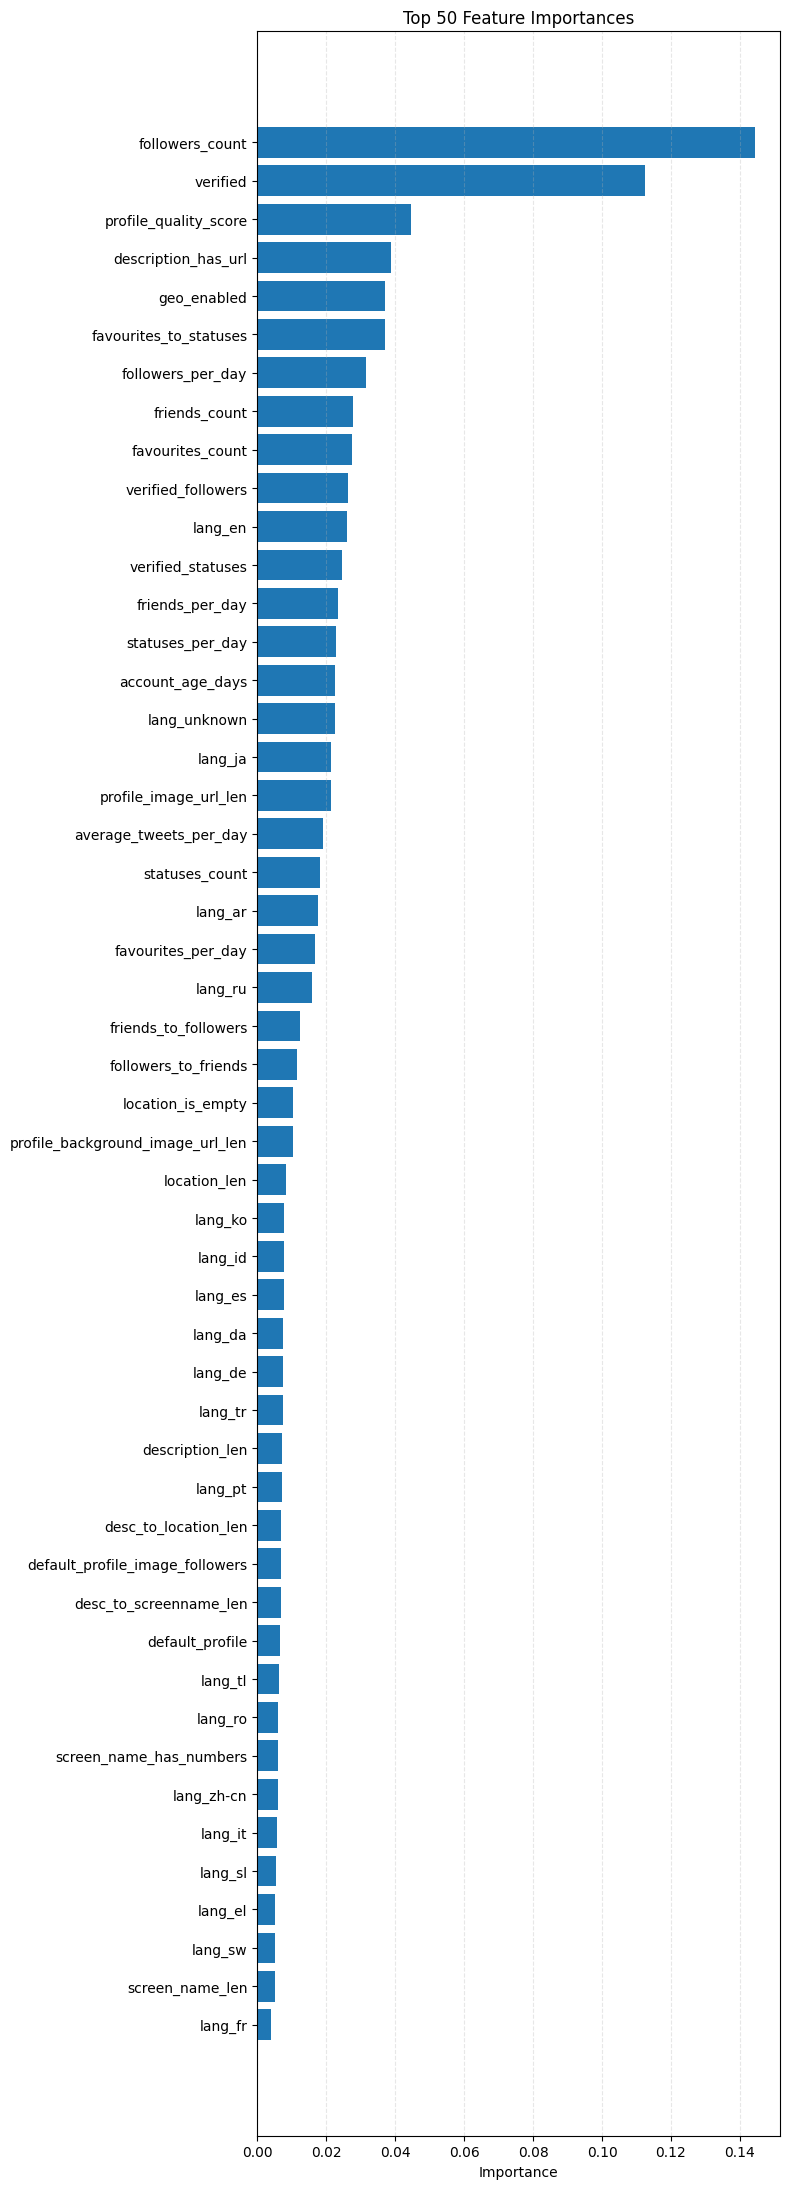

In [24]:
# Plot feature importances (uses importance_df created earlier)
# Show top N features as a horizontal bar chart
top_n = 50
top_df = importance_df.head(top_n).iloc[::-1]  # reverse for plotting

plt.figure(figsize=(8, 0.4 * len(top_df) + 2))
plt.barh(top_df['feature'], top_df['importance'], color='C0')
plt.xlabel('Importance')
plt.title(f'Top {top_n} Feature Importances')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Hyperparameter Optimization

### Optuna new should be faster

In [38]:
# Optuna-based hyperparameter optimization for XGBoost with NEW preprocessing method
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
import time
import warnings
import joblib
import os
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)

try:
    import GPUtil
    gpus = GPUtil.getGPUs()
    gpu_available = len(gpus) > 0
    if gpu_available:
        print(f"GPU detected: {gpus[0].name} with {gpus[0].memoryFree}MB free memory")
    else:
        print("No GPU detected, using CPU")
except ImportError:
    print("GPUtil not installed, assuming CPU usage")
    gpu_available = False

def perform_optuna_xgboost_optimization(raw_train_features, y_train, n_trials=50, cv_folds=5, use_gpu=True):
    
    print("="*70)
    print("OPTUNA HYPERPARAMETER OPTIMIZATION FOR XGBOOST")
    print("="*70)
    print("\nNEW METHOD: Pre-CV preprocessing + In-fold imputation/encoding")
    print("Optimizing for AUC score")
    
    if use_gpu and gpu_available:
        tree_method = 'gpu_hist'
        print(f"\nUsing GPU acceleration with tree_method='{tree_method}'")
    else:
        tree_method = 'hist'
        print(f"\nUsing CPU with tree_method='{tree_method}'")
    
    print("\n" + "="*70)
    print("STEP 1: PRE-CV PREPROCESSING")
    print("="*70)
    
    X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)
    
    print(f"\nPreprocessed shape: {X_preprocessed.shape}")
    print(f"Missing values: {X_preprocessed.isnull().sum().sum()}")
    
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    
    print("\n" + "="*70)
    print("STEP 2: OPTIMIZATION WITH IN-FOLD PROCESSING")
    print("="*70)
    print(f"\nOptimization Overview:")
    print(f"   Number of trials: {n_trials}")
    print(f"   Cross-validation folds: {cv_folds}")
    print(f"   Total model fits: {n_trials * cv_folds}")
    print(f"   Estimated time: {(n_trials * 30) / 60:.1f}-{(n_trials * 90) / 60:.1f} minutes\n")
    
    def objective(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 7),
            'gamma': trial.suggest_float('gamma', 0.0, 0.5),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
            'random_state': 42,
            'eval_metric': 'logloss',
            'tree_method': tree_method
        }
        
        if use_gpu and gpu_available:
            params['gpu_id'] = 0
        
        fold_scores_auc = []
        
        for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
            X_train_fold = X_preprocessed.iloc[train_idx]
            X_val_fold = X_preprocessed.iloc[val_idx]
            y_train_fold = y_train.iloc[train_idx]
            y_val_fold = y_train.iloc[val_idx]
            
            X_train_processed, X_val_processed, _ = in_fold_process_data(
                X_train_fold, X_val_fold,
                imputation_strategy='median',
                categorical_encoding='onehot',
                lang_frequency_threshold=0,
                scale_numerical=USE_SCALING,
                verbose=False
            )
            
            model = xgb.XGBClassifier(**params)
            model.fit(X_train_processed, y_train_fold)
            
            val_probabilities = model.predict_proba(X_val_processed)[:, 1]
            fold_score_auc = roc_auc_score(y_val_fold, val_probabilities)
            fold_scores_auc.append(fold_score_auc)
        
        mean_score_auc = np.mean(fold_scores_auc)
        return mean_score_auc
    
    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(seed=42)
    )
    
    print("Starting optimization...")
    start_time = time.time()
    
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    
    total_time = time.time() - start_time
    
    best_params = study.best_params
    best_score = study.best_value
    
    print("\n" + "="*70)
    print("OPTIMIZATION COMPLETE!")
    print("="*70)
    print(f"\nTotal time: {total_time/60:.1f} minutes ({total_time:.0f} seconds)")
    print(f"Best Cross-Validation AUC Score: {best_score:.4f}")
    print("\nBest Parameters:")
    for param, value in best_params.items():
        print(f"   {param}: {value}")
    
    print("\n" + "="*70)
    print("TRAINING FINAL MODEL WITH BEST PARAMETERS")
    print("="*70)
    
    best_params_full = best_params.copy()
    best_params_full.update({
        'random_state': 42,
        'eval_metric': 'logloss',
        'tree_method': tree_method
    })
    if use_gpu and gpu_available:
        best_params_full['gpu_id'] = 0
    
    print("\nPre-processing full training dataset...")
    X_preprocessed_full = preprocess_data(raw_train_features, verbose=False, include_statuses_count=True)
    
    print("Processing full dataset (imputation & encoding)...")
    dummy_val_idx = range(min(100, len(X_preprocessed_full)))
    X_train_full, _, _ = in_fold_process_data(
        X_preprocessed_full, 
        X_preprocessed_full.iloc[dummy_val_idx],
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        scale_numerical=USE_SCALING,
        verbose=True
    )
    
    print("Training final model...")
    best_model = xgb.XGBClassifier(**best_params_full)
    best_model.fit(X_train_full, y_train)
    
    train_predictions = best_model.predict(X_train_full)
    train_probabilities = best_model.predict_proba(X_train_full)[:, 1]
    train_accuracy = accuracy_score(y_train, train_predictions)
    train_auc = roc_auc_score(y_train, train_probabilities)
    
    print(f"Final model training accuracy: {train_accuracy:.4f}")
    print(f"Final model training AUC: {train_auc:.4f}")
    
    feature_importance = best_model.feature_importances_
    feature_names = X_train_full.columns
    importance_df_optuna = pd.DataFrame({
        'feature': feature_names,
        'importance': feature_importance
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features:")
    print(importance_df_optuna.head(10).to_string(index=False, float_format='%.4f'))
    
    print("\n" + "="*70)
    print("OPTIMIZATION HISTORY ANALYSIS")
    print("="*70)
    
    trials_df = study.trials_dataframe()
    print(f"\nNumber of completed trials: {len(study.trials)}")
    print(f"AUC score range: {trials_df['value'].min():.4f} - {trials_df['value'].max():.4f}")
    print(f"AUC score std: {trials_df['value'].std():.4f}")
    print(f"Best trial number: {study.best_trial.number + 1}")
    
    top_trials = trials_df.nlargest(5, 'value')[['value', 'number'] + 
                                                  [col for col in trials_df.columns if col.startswith('params_')]]
    print("\nTop 5 Trials:")
    print(top_trials.to_string(index=False, float_format='%.4f'))
    
    return best_model, best_params_full, best_score, study, X_train_full, importance_df_optuna

print("Starting Optuna hyperparameter optimization with NEW preprocessing method...\n")

raw_train_features = train.drop('target', axis=1)
y_train = train['target']

best_model_optuna, best_params_optuna, best_score_optuna, study_optuna, X_train_optuna, importance_df_optuna = perform_optuna_xgboost_optimization(
    raw_train_features, y_train, 
    n_trials=50,
    cv_folds=5, 
    use_gpu=True
)

print("\n" + "="*70)
print("GENERATING TEST PREDICTIONS")
print("="*70)

print("\nPre-processing test data...")
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

print("Applying imputation & encoding...")
dummy_val_idx = range(min(100, len(X_test_preprocessed)))
_, X_test_optuna, _ = in_fold_process_data(
    X_train_optuna.iloc[:100],
    X_test_preprocessed,
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    scale_numerical=USE_SCALING,
    verbose=False
)

print(f"\nProcessed test data shape: {X_test_optuna.shape}")
print(f"Training data shape: {X_train_optuna.shape}")

if X_train_optuna.shape[1] != X_test_optuna.shape[1]:
    print("\nAligning features...")
    missing_cols = set(X_train_optuna.columns) - set(X_test_optuna.columns)
    extra_cols = set(X_test_optuna.columns) - set(X_train_optuna.columns)
    
    for col in missing_cols:
        X_test_optuna[col] = 0
    for col in extra_cols:
        X_test_optuna = X_test_optuna.drop(columns=[col])
    
    X_test_optuna = X_test_optuna[X_train_optuna.columns]

print("\nConsistency check:")
print(f"  Same number of columns: {X_train_optuna.shape[1] == X_test_optuna.shape[1]}")
print(f"  Column names match: {list(X_train_optuna.columns) == list(X_test_optuna.columns)}")

print("\nGenerating predictions...")
start_time = time.time()
test_probabilities_optuna = best_model_optuna.predict_proba(X_test_optuna)[:, 1]
prediction_time = time.time() - start_time

print(f"Predictions complete in {prediction_time:.2f} seconds")
print("\nPrediction statistics:")
print(f"   Range: {test_probabilities_optuna.min():.4f} to {test_probabilities_optuna.max():.4f}")
print(f"   Mean: {test_probabilities_optuna.mean():.4f}")
print(f"   Std: {test_probabilities_optuna.std():.4f}")

submission_optuna = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities_optuna
})

os.makedirs('../submissions', exist_ok=True)
submission_path_optuna = '../submissions/XGBoost_optuna_NEW.csv'
submission_optuna.to_csv(submission_path_optuna, index=False)

os.makedirs('trained', exist_ok=True)
model_path_optuna = 'trained/xgb_model_optuna_NEW.joblib'
joblib.dump(best_model_optuna, model_path_optuna)

study_path = 'trained/optuna_study_NEW.joblib'
joblib.dump(study_optuna, study_path)

print(f"\nSubmission saved to: {submission_path_optuna}")
print(f"Optuna-tuned model saved to: {model_path_optuna}")
print(f"Optuna study saved to: {study_path}")

print("\nFirst 10 predictions:")
print(submission_optuna.head(10))

print("\n" + "="*70)
print("OPTUNA OPTIMIZATION COMPLETE!")
print("="*70)
print(f"\nBest CV AUC Score: {best_score_optuna:.4f}")
print("\nYou can visualize the optimization history using:")
print("   optuna.visualization.plot_optimization_history(study_optuna)")
print("   optuna.visualization.plot_param_importances(study_optuna)")
print("\nTo reload the saved study later:")
print(f"   study = joblib.load('{study_path}')")

GPUtil not installed, assuming CPU usage
Starting Optuna hyperparameter optimization with NEW preprocessing method...

OPTUNA HYPERPARAMETER OPTIMIZATION FOR XGBOOST

NEW METHOD: Pre-CV preprocessing + In-fold imputation/encoding
Optimizing for AUC score

Using CPU with tree_method='hist'

STEP 1: PRE-CV PREPROCESSING
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)


[I 2025-10-07 15:18:50,123] A new study created in memory with name: no-name-2440a8a1-252b-4954-99de-9beb374cab18


  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (49 categories)

Extracting textual features...
  - location_len: mean=11.05
  - description_len: mean=66.79
  - screen_name_len: mean=11.12
  - profile_background_image_url_len: mean=42.25
  - profile_image_url_len: mean=75.52
  - description_has_url: 3613 accounts (13.8%)
  - screen_name_has_numbers: 7015 accounts (26.8%)
  - location_is_empty: 9219 accounts (35.2%)
  - description_is_empty: 5091 accounts (19.4%)

Engineering features...
  - followers_per_day: mean=100.1868
  - friends_per_day: mean=1.3514
  - statuses_per_day: mean=6.7520
  - favourites_per_day: mean=4.5426
  - followers_to_friends: mean=17068.7325
  - friends_to_followers: mean=2.4651
  - favourites_to_statuses: mean=2.3652
  - default_profile_image_followers: mean=156.1863
  - verified_followers: mean=349050.1084
  - verified_statuses: mean=6533.1420
  - desc_to_screenname_len: mean=

Best trial: 0. Best value: 0.943352:   2%|▏         | 1/50 [00:06<05:18,  6.50s/it]

[I 2025-10-07 15:18:56,624] Trial 0 finished with value: 0.9433517495290673 and parameters: {'n_estimators': 250, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.02904180608409973, 'reg_alpha': 0.8661761457749352, 'reg_lambda': 0.6011150117432088}. Best is trial 0 with value: 0.9433517495290673.


...

[I 2025-10-07 15:24:49,803] Trial 47 finished with value: 0.9405579610338426 and parameters: {'n_estimators': 450, 'max_depth': 8, 'learning_rate': 0.1472329029509108, 'subsample': 0.8252523496757214, 'colsample_bytree': 0.7537222511006231, 'min_child_weight': 3, 'gamma': 0.08573885876176274, 'reg_alpha': 0.835903037947658, 'reg_lambda': 0.5133518777683586}. Best is trial 11 with value: 0.9473212214467341.


Best trial: 11. Best value: 0.947321:  98%|█████████▊| 49/50 [06:08<00:08,  8.27s/it]

[I 2025-10-07 15:24:58,604] Trial 48 finished with value: 0.9468675333798015 and parameters: {'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.028253071794473988, 'subsample': 0.7385995495504231, 'colsample_bytree': 0.6969857493349224, 'min_child_weight': 5, 'gamma': 0.028211692666379767, 'reg_alpha': 0.5897722148126632, 'reg_lambda': 0.1928493576831385}. Best is trial 11 with value: 0.9473212214467341.


Best trial: 11. Best value: 0.947321: 100%|██████████| 50/50 [06:15<00:00,  7.51s/it]


[I 2025-10-07 15:25:05,785] Trial 49 finished with value: 0.9463593935520617 and parameters: {'n_estimators': 450, 'max_depth': 7, 'learning_rate': 0.037442201865860184, 'subsample': 0.7936674388091226, 'colsample_bytree': 0.8260030273587511, 'min_child_weight': 5, 'gamma': 0.4123740184431729, 'reg_alpha': 0.557697428812737, 'reg_lambda': 0.3481634963661079}. Best is trial 11 with value: 0.9473212214467341.

OPTIMIZATION COMPLETE!

Total time: 6.3 minutes (376 seconds)
Best Cross-Validation AUC Score: 0.9473

Best Parameters:
   n_estimators: 500
   max_depth: 8
   learning_rate: 0.02304364042504696
   subsample: 0.6105733875603306
   colsample_bytree: 0.8222008072142497
   min_child_weight: 5
   gamma: 0.1536483060584243
   reg_alpha: 0.47213769628665514
   reg_lambda: 0.7066301096506243

TRAINING FINAL MODEL WITH BEST PARAMETERS

Pre-processing full training dataset...
Processing full dataset (imputation & encoding)...
=== In-Fold Processing (Fit on Train, Transform Train & Val) ===


In [26]:
# Visualize Optuna optimization results
# Note: If you get nbformat errors, run: pip install --upgrade nbformat
import joblib
import optuna

study_optuna = joblib.load('trained/optuna_study.joblib')
try:
    import plotly
    fig1 = optuna.visualization.plot_optimization_history(study_optuna)
    fig1.show()
    
    fig2 = optuna.visualization.plot_param_importances(study_optuna)
    fig2.show()
except Exception as e:
    print(f"Visualization error: {e}")
    print("\nTo fix this, run in terminal:")
    print("  pip install --upgrade nbformat plotly")
    print("\nAlternatively, you can view the optimization results as text:")
    print(f"\nBest trial: {study_optuna.best_trial.number}")
    print(f"Best value: {study_optuna.best_value:.4f}")
    print(f"Best params: {study_optuna.best_params}")


Loaded baseline model from: trained/xgb_model.joblib
Top 20 features (baseline model):
------------------------------------------------------------
               feature  importance
       followers_count    0.144400
              verified    0.112553
 profile_quality_score    0.044712
   description_has_url    0.038853
           geo_enabled    0.037199
favourites_to_statuses    0.037157
     followers_per_day    0.031485
         friends_count    0.027858
      favourites_count    0.027498
    verified_followers    0.026417
               lang_en    0.025992
     verified_statuses    0.024486
       friends_per_day    0.023509
      statuses_per_day    0.022822
      account_age_days    0.022603
          lang_unknown    0.022465
               lang_ja    0.021533
 profile_image_url_len    0.021531
average_tweets_per_day    0.018988
        statuses_count    0.018144

Top 20 features (Optuna-tuned model):
------------------------------------------------------------
                 

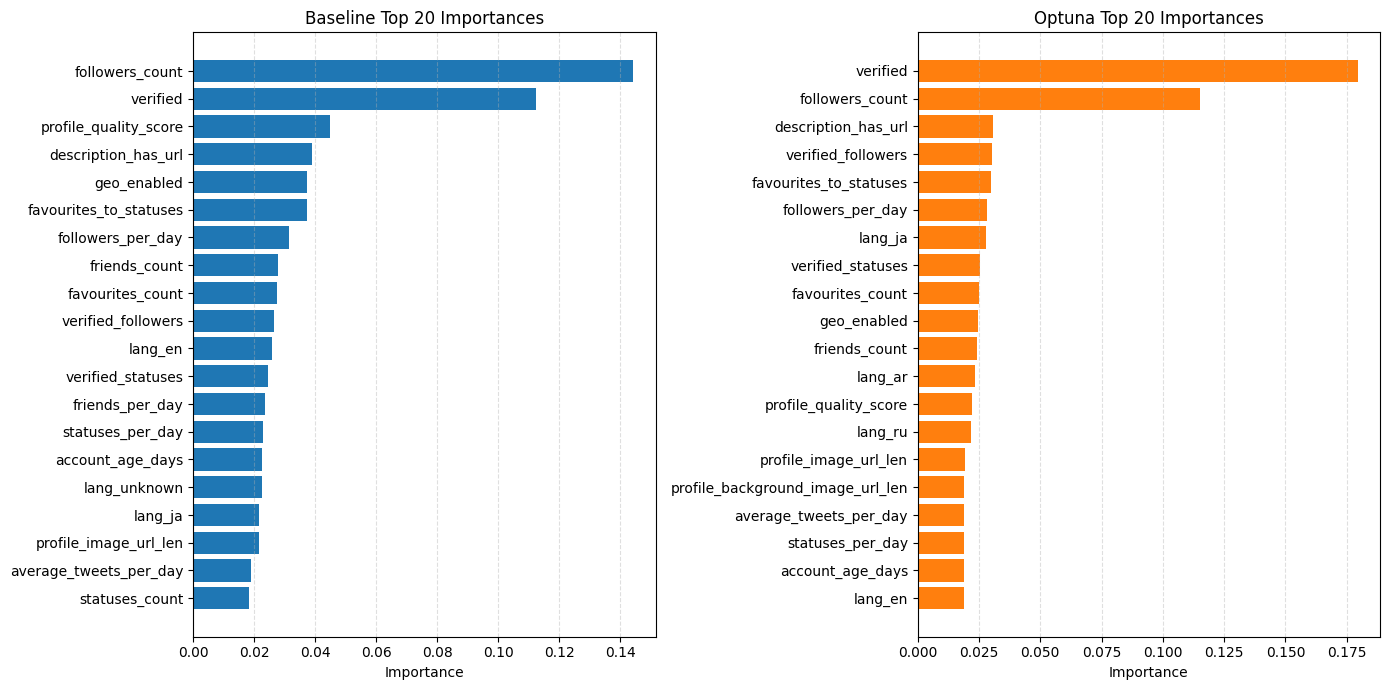

In [28]:
# Check and visualize feature importances for baseline and Optuna-tuned models
top_n = 20

# load baseline model (use existing model_path if available)
baseline_model_path = globals().get('model_path', 'trained/xgb_model.joblib')
baseline_model = joblib.load(baseline_model_path)
print(f"Loaded baseline model from: {baseline_model_path}")

# ensure importance_df matches the loaded model's feature importances
try:
    fi = baseline_model.feature_importances_
    if 'X_train' in globals():
        cols = X_train.columns
    else:
        cols = globals().get('feature_names', None)
    if cols is not None and len(fi) == len(cols):
        importance_df = pd.DataFrame({'feature': cols, 'importance': fi}) \
                         .sort_values('importance', ascending=False) \
                         .reset_index(drop=True)
    else:
        print("Warning: cannot rebuild importance_df — feature names length mismatch or missing.")
except Exception as e:
    print(f"Could not extract feature_importances_ from loaded model: {e}")
    
print("="*60)
print(f"Top {top_n} features (baseline model):")
print("-"*60)
print(importance_df.head(top_n).to_string(index=False, float_format='%.6f'))

print("\n" + "="*60)
print(f"Top {top_n} features (Optuna-tuned model):")
print("-"*60)
print(importance_df_optuna.head(top_n).to_string(index=False, float_format='%.6f'))

# How many features explain 90% of importance
def features_for_threshold(df, threshold=0.90):
    s = df.sort_values('importance', ascending=False).reset_index(drop=True)
    s['cum_importance'] = s['importance'].cumsum()
    idx = s[s['cum_importance'] >= threshold].index
    if len(idx) == 0:
        return len(s), s
    n_feats = int(idx[0]) + 1
    return n_feats, s

n_base, s_base = features_for_threshold(importance_df, 0.90)
n_opt, s_opt = features_for_threshold(importance_df_optuna, 0.90)

print("\n" + "="*60)
print(f"Features needed to reach 90% cumulative importance:")
print(f"  Baseline model: {n_base} features")
print(f"  Optuna model:   {n_opt} features")

# List zero-importance features (if any)
zeros_base = importance_df[importance_df['importance'] == 0]['feature'].tolist()
zeros_opt = importance_df_optuna[importance_df_optuna['importance'] == 0]['feature'].tolist()

print("\nZero-importance features:")
print(f"  Baseline ({len(zeros_base)}): {zeros_base[:10]}{'...' if len(zeros_base)>10 else ''}")
print(f"  Optuna  ({len(zeros_opt)}): {zeros_opt[:10]}{'...' if len(zeros_opt)>10 else ''}")

# Side-by-side horizontal bar plots for the top features
fig, axes = plt.subplots(1, 2, figsize=(14, max(6, 0.35 * top_n)))
# Baseline
top_base = importance_df.head(top_n).iloc[::-1]
axes[0].barh(top_base['feature'], top_base['importance'], color='C0')
axes[0].set_title(f'Baseline Top {top_n} Importances')
axes[0].set_xlabel('Importance')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)
# Optuna
top_opt = importance_df_optuna.head(top_n).iloc[::-1]
axes[1].barh(top_opt['feature'], top_opt['importance'], color='C1')
axes[1].set_title(f'Optuna Top {top_n} Importances')
axes[1].set_xlabel('Importance')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Old Grid Search

In [27]:
# # Grid Search function with fold-wise preprocessing for better data leakage prevention
# from sklearn.model_selection import GridSearchCV, StratifiedKFold
# from sklearn.base import BaseEstimator, TransformerMixin
# import time

# # Check for GPU availability
# try:
#     import GPUtil
#     gpus = GPUtil.getGPUs()
#     gpu_available = len(gpus) > 0
#     if gpu_available:
#         print(f"GPU detected: {gpus[0].name} with {gpus[0].memoryFree}MB free memory")
#     else:
#         print("No GPU detected, using CPU")
# except ImportError:
#     print("GPUtil not installed, assuming CPU usage")
#     gpu_available = False

# class VerboseXGBoostWithPreprocessing(BaseEstimator):
#     """
#     Custom estimator that combines preprocessing and XGBoost training with verbose logging.
#     This ensures preprocessing happens within each CV fold to prevent data leakage.
#     """
    
#     def __init__(self, n_estimators=100, max_depth=6, learning_rate=0.1, 
#                  subsample=0.8, colsample_bytree=0.8, min_child_weight=1, 
#                  random_state=42, eval_metric='logloss', tree_method='auto',
#                  gpu_id=0, fold_id=None, param_combo_id=None):
#         # Store all parameters as instance attributes (required for scikit-learn)
#         self.n_estimators = n_estimators
#         self.max_depth = max_depth
#         self.learning_rate = learning_rate
#         self.subsample = subsample
#         self.colsample_bytree = colsample_bytree
#         self.min_child_weight = min_child_weight
#         self.random_state = random_state
#         self.eval_metric = eval_metric
#         self.tree_method = tree_method
#         self.gpu_id = gpu_id
#         self.fold_id = fold_id
#         self.param_combo_id = param_combo_id
        
#         # Initialize private attributes for fitted state
#         self.feature_list_ = None
#         self.model_ = None
#         self.preprocessing_time_ = 0
#         self.training_time_ = 0
    
#     def fit(self, X_raw, y):
#         """
#         Fit the model with preprocessing applied to raw data.
#         """
#         # Track preprocessing time
#         preprocess_start = time.time()
        
#         if self.fold_id is not None and self.param_combo_id is not None:
#             print(f"Fold {self.fold_id}: Preprocessing {X_raw.shape[0]} samples...")
        
#         # Process raw training data to get features and feature list
#         X_processed, self.feature_list_ = process_data(X_raw, verbose=False)
        
#         self.preprocessing_time_ = time.time() - preprocess_start
        
#         if self.fold_id is not None:
#             print(f"Fold {self.fold_id}: Preprocessing complete ({self.preprocessing_time_:.2f}s) -> {X_processed.shape[1]} features")
        
#         # Track training time
#         train_start = time.time()
        
#         if self.fold_id is not None:
#             device_info = f"GPU {self.gpu_id}" if self.tree_method in ['gpu_hist', 'gpu_exact'] else "CPU"
#             print(f"Fold {self.fold_id}: Training XGBoost on {device_info}...")
        
#         # Initialize and train XGBoost model with GPU support if available
#         self.model_ = xgb.XGBClassifier(
#             n_estimators=self.n_estimators,
#             max_depth=self.max_depth,
#             learning_rate=self.learning_rate,
#             subsample=self.subsample,
#             colsample_bytree=self.colsample_bytree,
#             min_child_weight=self.min_child_weight,
#             random_state=self.random_state,
#             eval_metric=self.eval_metric,
#             tree_method=self.tree_method,
#             gpu_id=self.gpu_id if self.tree_method in ['gpu_hist', 'gpu_exact'] else None
#         )
        
#         self.model_.fit(X_processed, y)
        
#         self.training_time_ = time.time() - train_start
        
#         if self.fold_id is not None:
#             print(f"Fold {self.fold_id}: Training complete ({self.training_time_:.2f}s)")
        
#         return self
    
#     def predict(self, X_raw):
#         """
#         Make predictions on raw data (applies preprocessing first).
#         """
#         X_processed = process_data(
#             X_raw, verbose=False, expected_features=self.feature_list_
#         )
#         return self.model_.predict(X_processed)
    
#     def predict_proba(self, X_raw):
#         """
#         Make probability predictions on raw data (applies preprocessing first).
#         """
#         X_processed = process_data(
#             X_raw, verbose=False, expected_features=self.feature_list_
#         )
#         return self.model_.predict_proba(X_processed)
    
#     def get_params(self, deep=True):
#         """Get parameters for GridSearchCV - must return all __init__ parameters."""
#         params = {
#             'n_estimators': self.n_estimators,
#             'max_depth': self.max_depth,
#             'learning_rate': self.learning_rate,
#             'subsample': self.subsample,
#             'colsample_bytree': self.colsample_bytree,
#             'min_child_weight': self.min_child_weight,
#             'random_state': self.random_state,
#             'eval_metric': self.eval_metric,
#             'tree_method': self.tree_method,
#             'gpu_id': self.gpu_id,
#             'fold_id': self.fold_id,
#             'param_combo_id': self.param_combo_id
#         }
#         return params
    
#     def set_params(self, **params):
#         """Set parameters for GridSearchCV - must handle all valid parameter names."""
#         valid_params = {
#             'n_estimators', 'max_depth', 'learning_rate', 'subsample', 
#             'colsample_bytree', 'min_child_weight', 'random_state', 
#             'eval_metric', 'tree_method', 'gpu_id', 'fold_id', 'param_combo_id'
#         }
        
#         for key, value in params.items():
#             if key in valid_params:
#                 setattr(self, key, value)
#             else:
#                 raise ValueError(f"Invalid parameter {key} for estimator {self.__class__.__name__}")
        
#         return self

# def perform_robust_xgboost_grid_search(raw_train_features, y_train, cv_folds=5, use_gpu=True):
#     """
#     Perform grid search for XGBoost with fold-wise preprocessing to prevent data leakage.
    
#     Parameters:
#     raw_train_features: Raw training features (before preprocessing)
#     y_train: Training target
#     cv_folds: Number of cross-validation folds
#     use_gpu: Whether to use GPU acceleration if available
    
#     Returns:
#     best_model: Best XGBoost model from grid search
#     best_params: Best parameters found
#     best_score: Best cross-validation score
#     """
    
#     print("Starting XGBoost Grid Search with fold-wise preprocessing...")
#     print("This prevents data leakage by preprocessing within each CV fold.")
#     print("This may take longer but provides more reliable results.")
    
#     # Determine tree method based on GPU availability and user preference
#     if use_gpu and gpu_available:
#         tree_method = 'gpu_hist'  # Best GPU method for most cases
#         n_jobs = 1  # GPU doesn't benefit from multiple jobs
#         print(f"Using GPU acceleration with tree_method='{tree_method}'")
#     else:
#         tree_method = 'hist'  # Fast CPU method
#         n_jobs = -1  # Use all CPU cores
#         print(f"Using CPU with tree_method='{tree_method}' and all available cores")
    
#     # Define parameter grid - you can modify these based on your needs
#     param_grid = {
#         'n_estimators': [100, 200, 300],
#         'max_depth': [4, 6, 8],
#         'learning_rate': [0.05, 0.1, 0.2],
#         'subsample': [0.8, 0.9, 1.0],
#         'colsample_bytree': [0.8, 0.9, 1.0],
#         'min_child_weight': [1, 3, 5]
#     }
    
#     # For faster testing, you can use a smaller grid:
#     # param_grid = {
#     #     'n_estimators': [100, 200],
#     #     'max_depth': [4, 6],
#     #     'learning_rate': [0.1, 0.2]
#     # }
    
#     # Initialize custom estimator with preprocessing
#     estimator = VerboseXGBoostWithPreprocessing(
#         random_state=42, 
#         eval_metric='logloss', 
#         tree_method=tree_method,
#         gpu_id=0 if use_gpu and gpu_available else None
#     )
    
#     # Setup cross-validation
#     skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    
#     # Calculate total combinations for overview
#     total_combinations = 1
#     for param_values in param_grid.values():
#         total_combinations *= len(param_values)
    
#     print("\nGrid Search Overview:")
#     print(f"   Parameter combinations: {total_combinations}")
#     print(f"   Cross-validation folds: {cv_folds}")
#     print(f"   Total model fits: {total_combinations * cv_folds}")
#     print("   Estimated time per combination: 30-120 seconds")
#     print(f"   Estimated total time: {(total_combinations * 60) / 60:.1f}-{(total_combinations * 120) / 60:.1f} minutes")
#     print()
    
#     # Initialize GridSearchCV with verbose logging (using standard GridSearchCV)
#     grid_search = GridSearchCV(
#         estimator=estimator,
#         param_grid=param_grid,
#         scoring='accuracy',
#         cv=skf,
#         n_jobs=n_jobs,
#         verbose=2,
#         return_train_score=True
#     )
    
#     # Start grid search
#     print(f"Starting grid search...")
#     start_time = time.time()
    
#     grid_search.fit(raw_train_features, y_train)
    
#     total_time = time.time() - start_time
    
#     # Get results
#     best_model = grid_search.best_estimator_
#     best_params = grid_search.best_params_
#     best_score = grid_search.best_score_
    
#     print("\nGrid Search Complete!")
#     print(f"Total time: {total_time/60:.1f} minutes ({total_time:.0f} seconds)")
#     print(f"Best Cross-Validation Score: {best_score:.4f}")
#     print("Best Parameters:")
#     for param, value in best_params.items():
#         print(f"   {param}: {value}")
    
#     # Analyze results
#     results_df = pd.DataFrame(grid_search.cv_results_)
    
#     print("\nGrid Search Analysis:")
#     print(f"   Mean fit time per combination: {results_df['mean_fit_time'].mean():.2f}s")
#     print(f"   Mean score time per combination: {results_df['mean_score_time'].mean():.2f}s")
#     print(f"   Best score rank: 1 out of {len(results_df)}")
#     print(f"   Score range: {results_df['mean_test_score'].min():.4f} - {results_df['mean_test_score'].max():.4f}")
#     print(f"   Score std: {results_df['mean_test_score'].std():.4f}")
    
#     # Show top 5 parameter combinations
#     top_results = results_df.nlargest(5, 'mean_test_score')[
#         ['mean_test_score', 'std_test_score', 'mean_fit_time'] + 
#         [col for col in results_df.columns if col.startswith('param_')]
#     ]
#     print("\nTop 5 Parameter Combinations:")
#     print(top_results.to_string(index=False, float_format='%.4f'))
    
#     # Get feature importance from the best model (need to access the internal XGBoost model)
#     if hasattr(best_model, 'model_') and best_model.model_ is not None:
#         feature_importance = best_model.model_.feature_importances_
#         feature_names = best_model.feature_list_
#         importance_df = pd.DataFrame({
#             'feature': feature_names,
#             'importance': feature_importance
#         }).sort_values('importance', ascending=False)
        
#         print("\nTop 10 Most Important Features (Best Model):")
#         print(importance_df.head(10).to_string(index=False, float_format='%.4f'))
    
#     return best_model, best_params, best_score

# # Usage example:
# # Prepare raw data for grid search (same as Cell 4)
# raw_train_features = train.drop('target', axis=1)
# y_train = train['target']

# print("Starting grid search...")
# best_model_robust, best_params_robust, best_score_robust = perform_robust_xgboost_grid_search(
#     raw_train_features, y_train, cv_folds=5, use_gpu=True
# )

# # Generate improved predictions with best model
# print("\nGenerating predictions with best model...")
# start_time = time.time()
# test_probabilities_robust = best_model_robust.predict_proba(test)[:, 1]
# prediction_time = time.time() - start_time

# print(f"Predictions complete in {prediction_time:.2f} seconds")
# print("Prediction statistics:")
# print(f"   Range: {test_probabilities_robust.min():.4f} to {test_probabilities_robust.max():.4f}")
# print(f"   Mean: {test_probabilities_robust.mean():.4f}")
# print(f"   Std: {test_probabilities_robust.std():.4f}")

# # Create improved submission
# submission_robust = pd.DataFrame({
#     'index': test['index'],
#     'target': test_probabilities_robust
# })

# submission_robust.to_csv('XGBoost_gs.csv', index=False)
# print("submission saved as: XGBoost_gs.csv")

# print("\n" + "="*50)
# print("GRID SEARCH COMPLETE!")
# print("="*50)